# Palmer Penguins: supervised learning
Author: Marcos Robinat. PRDL and MLLB, 2026-2027.

This study asks whether physical measurements predict species and body mass better than simple references. Classification compares **logistic regression, a decision tree, linear SVM, KNN and Random Forest** under one common evaluation protocol. Regression compares ordinary least squares with a median reference.

**Contents:** 1. Data and preparation; 2. Shared evaluation methodology; 3. Classification models; 4. Training and comparison; 5. Reading fitted models; 6. Regression; 7. Reserved-test evaluation; 8. Uncertainty; 9. Conclusions and references.

Run all cells from a fresh CPU runtime with the unchanged penguins.csv. This notebook is independent of the other notebooks' runtime variables. It uses pandas, NumPy, Matplotlib, scikit-learn and SciPy. Data, settings and results are the same verified study; the presentation follows the scientific questions rather than a development diary.


In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

print('Python:', platform.python_version())
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


Python: 3.12.14
pandas: 2.3.3
NumPy: 2.5.3
scikit-learn: 1.9.1


## 1. Data and preparation


The authors' simplified table has 344 observations and eight columns. The hash below identifies the exact project CSV, not its scientific quality. Parsing `NA` as missing does not fill or remove any values. Source: [Palmer Penguins documentation](https://allisonhorst.github.io/palmerpenguins/), CC0 data; acknowledge Horst, Hill and Gorman and the original collectors. The original ecological study is [Gorman et al. (2014)](https://doi.org/10.1371/journal.pone.0090081).

In [2]:
DATA_PATH = Path('penguins.csv')
EXPECTED_SHA256 = 'f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93'
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError('Place the original penguins.csv beside this notebook.') from error
    print('Upload the unchanged penguins.csv from the Penguins_ML folder.')
    files.upload()
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if source_hash != EXPECTED_SHA256:
    raise ValueError('The CSV differs from the recorded source. Check before continuing.')
penguins = pd.read_csv(DATA_PATH, na_values=['NA'])
print('SHA-256:', source_hash)
print('Source dimensions:', penguins.shape)
assert penguins.shape == (344, 8)

SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93
Source dimensions: (344, 8)


### 1.1 Development and reserved test

The original 344 rows are allocated once: **275 to training/development and 69 to a reserved final test**. `test_size=0.20` means about 20% is reserved; seed 42 makes the allocation reproducible. `stratify=species` approximately preserves species proportions; it does not artificially balance them.

We construct only the training table below. The final test will answer a later question: how do our fixed choices behave on reserved observations? It is **not** used to choose settings or compare methods during development.

Notebook 01 disclosed basic whole-table ingestion checks before analytical EDA. Therefore, we do not claim that the test has never been inspected historically. It is excluded from analytical EDA, model fitting, tuning and the development evaluations. Section 7 uses it for the final assessment after decisions and fits are fixed. Original row IDs identify CSV records, not model inputs or guaranteed independent biological individuals. This random split addresses within-sample performance, not new islands or future years.

In [3]:
SEED = 42
FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
TARGET = 'species'
CLASS_ORDER = ['Adelie', 'Chinstrap', 'Gentoo']
train_ids, test_ids = train_test_split(
    penguins.index.to_numpy(), test_size=0.20, random_state=SEED,
    stratify=penguins[TARGET],
)
train_ids = sorted(int(i) for i in train_ids)
test_ids = sorted(int(i) for i in test_ids)
assert set(train_ids).isdisjoint(test_ids)
assert sorted(train_ids + test_ids) == list(penguins.index)
train = penguins.loc[train_ids].copy()
print('Training allocation:', len(train))
print('Final-test IDs reserved:', len(test_ids))

Training allocation: 275
Final-test IDs reserved: 69


### 1.2 Required measurements and separate response

An observation is eligible here if its four physical inputs are recorded. This is **not** `dropna()` across all eight columns. Missing sex alone does not exclude an observation. The mask creates a separate modelling view; `penguins`, `train` and the CSV are not overwritten.

The excluded rows retain their source IDs for explanation. Replacing four absent physical inputs with medians would create a fully synthetic profile. Complete-case evaluation has a limitation too: it does not establish performance on observations without measurements or prove that missingness is random.

`train` is a DataFrame containing the 275 development observations, not a training function. The eligibility mask selects the 273 rows used for fitting and validation without changing that table. Training happens later when an estimator calls `.fit(X_fit, y_fit)`. Run the notebook from the top so that the source and split have been created before this cell.

In [4]:
eligible_mask = train[FEATURES].notna().all(axis=1)
training_view = train.loc[eligible_mask].copy()
excluded_training_ids = train.index[~eligible_mask].tolist()
X_train = training_view[FEATURES].copy()
y_train = training_view[TARGET].copy()

assert TARGET not in X_train.columns
assert X_train.index.equals(y_train.index)
assert X_train.notna().all().all()
assert set(X_train.index).isdisjoint(test_ids)
assert len(training_view) + len(excluded_training_ids) == len(train)
print('Training allocated / eligible / excluded:', len(train), len(training_view), len(excluded_training_ids))
print('Excluded source row IDs:', excluded_training_ids)
print('Eligible rows with missing sex retained:', int(training_view['sex'].isna().sum()))
display(y_train.value_counts().reindex(CLASS_ORDER).rename('eligible_training_count').to_frame())
print('Input matrix:', X_train.shape, '| Target:', y_train.shape)
assert len(training_view) == 273 and excluded_training_ids == [3, 271]

Training allocated / eligible / excluded: 275 273 2
Excluded source row IDs: [3, 271]
Eligible rows with missing sex retained: 9


,eligible_training_count
species,
Adelie,121
Chinstrap,54
Gentoo,98


Input matrix: (273, 4) | Target: (273,)


### 1.3 Scope of the inputs
Classification uses bill length, bill depth, flipper length and body mass. Regression removes body mass from the inputs when it becomes the response. Island, sex and year remain context variables in the source. Missing sex alone excludes no otherwise usable observation. Source rows 3 and 271 are excluded only from complete-measurement development views; no CSV row or recorded extreme is changed. Complete-case evaluation describes observations with the required measurements.

A learned parameter is estimated by `fit`; a hyperparameter is chosen between fits. Choosing a tree depth is different from learning its thresholds. An optimiser updates learned quantities inside a fit; it does not automatically choose every model's hyperparameters.


## 2. Shared evaluation methodology

The 273 eligible development observations support all five classifier procedures. **Five outer stratified folds assess them; three inner stratified folds select settings within each outer fit group.** All classifiers share outer held-out observations. Scalers are inside pipelines, so inner validation and outer held-out inputs never teach their fitted means or scales. The reserved 69-row test is excluded from all fitting and selection.

In outer round r, fit/select on the other four outer groups, then predict group r. Those predictions are out-of-fold (OOF). Every eligible row is assessed once per procedure. Rounds are separate fits on overlapping samples, not epochs or statistically independent experiments. The reference also uses the outer fit group's majority class.

Regression has no hyperparameter search: a separate five-fold KFold list assesses its fixed median/OLS methods. Continuous mass is not stratified. The original development/test allocation remains the same for both tasks.


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
fold_assignment = np.full(len(X_train), -1, dtype=int)
fold_rows = []
for fold_number, (fit_positions, validation_positions) in enumerate(folds, start=1):
    fit_ids = X_train.index[fit_positions]
    validation_ids = X_train.index[validation_positions]
    assert set(fit_ids).isdisjoint(validation_ids)
    assert set(fit_ids).union(validation_ids) == set(X_train.index)
    assert set(validation_ids).isdisjoint(test_ids)
    assert (fold_assignment[validation_positions] == -1).all()
    fold_assignment[validation_positions] = fold_number
    counts = y_train.iloc[validation_positions].value_counts().reindex(CLASS_ORDER, fill_value=0)
    fold_rows.append({'fold': fold_number, 'fit_n': len(fit_positions),
                      'validation_n': len(validation_positions), **counts.to_dict()})
assert (fold_assignment > 0).all()
fold_table = pd.DataFrame(fold_rows).set_index('fold')
display(fold_table)
assert int(fold_table['validation_n'].sum()) == len(X_train)

,fit_n,validation_n,Adelie,Chinstrap,Gentoo
fold,,,,,
1,218,55,25,11,19
2,218,55,24,11,20
3,218,55,24,11,20
4,219,54,24,10,20
5,219,54,24,11,19


### 2.1 Classification metrics

**Start with the confusion matrix:** rows are true species; columns are predicted species. Diagonal entries are correct predictions; off-diagonal entries are errors. All entries together count the 273 observations.

For one species at a time, treat it as **this species versus the other two**:

- **TP (true positives):** actually this species and predicted as this species.
- **FP (false positives):** another species, incorrectly predicted as this species.
- **FN (false negatives):** actually this species, incorrectly predicted as another.
- **Support:** the number of true observations of the species, $TP+FN$.

$$\mathrm{Accuracy}=\frac{\text{number of correct predictions}}{\text{number of predictions}}.$$

$$\mathrm{Precision}=\frac{TP}{TP+FP},\qquad \mathrm{Recall}=\frac{TP}{TP+FN}.$$

Recall is also called **sensitivity** or the true-positive rate for the species being considered. Precision asks: **of those called this species, how many really are?** Recall asks: **of this true species, how many did we find?**

$$F1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}=\frac{2TP}{2TP+FP+FN}.$$

F1 is the harmonic mean, not the ordinary arithmetic mean. It is high only when both precision and recall are high. Scores range from 0 to 1; accuracy may also be displayed as a percentage.

**Our three-species problem has three F1 scores.** We show precision, recall and F1 **for each species first**. If we also want one summary number, we must state how we combine them:

$$F1_{\mathrm{macro}}=\frac{F1_{\mathrm{Adelie}}+F1_{\mathrm{Chinstrap}}+F1_{\mathrm{Gentoo}}}{3}.$$

Thus **macro-F1 is just the equal-weight average of the three ordinary F1 scores**, not a different model or a different per-class F1 formula. We keep it as a labelled secondary summary, rather than calling an unspecified average simply "F1" or changing the problem to binary classification. We do not introduce other averaging variants here.

**Worked reference example:** always predicting Adelie gives $TP=121$, $FP=152$, $FN=0$ for Adelie. Its precision is $121/273=0.4432$, recall is $121/121=1$, and F1 is $242/394=0.6142$. Chinstrap and Gentoo each have F1 = 0. Therefore the mean of the three F1 scores is $(0.6142+0+0)/3=0.2047$.

No Chinstrap or Gentoo is predicted, so their precision has a zero denominator and is undefined mathematically. We explicitly report 0 using `zero_division=0`. Their F1 is 0 because they have true observations but none are recovered. Accuracy alone hides this failure. All scores below use held-out training predictions, not final-test predictions.

The main reading sequence is confusion counts, overall accuracy and sensitivity/recall for each species. F1 and its explicitly labelled mean provide a supplementary summary. Matrix orientation must always be stated: our implementation uses true classes on rows and predictions on columns; some textbooks or software reverse them. Reversing axes changes where FP and FN are read, not the definitions.

### 2.2 Hyperparameter selection and the reserved-test rule

Five outer stratified folds evaluate each procedure. Inside each outer fit group, three stratified folds select settings by **mean per-species F1 (macro-F1)**. Only then is the chosen pipeline refitted on that outer fit group and used to predict the outer held-out group. The scaler is inside the pipeline, so it is also refitted separately inside every inner fit.

| Family | Small, fixed search |
|---|---|
| Logistic regression | C = 0.1, 1, 10 |
| Linear SVM | C = 0.1, 1, 10 |
| Decision tree | depth = 2, 3, 4, 5; minimum leaf = 5 |
| KNN | neighbours = 3, 5, 9; uniform votes |
| Random Forest | 100 trees; depth = 3 or unrestricted; minimum leaf = 1 or 5 |

These are **hyperparameters**, chosen between fits. `fit` learns coefficients, stored neighbours or tree splits within a fit. The five outer rounds are not epochs. Regression remains untuned OLS and does not require an inner search.

**Final rules, fixed before test access:** choose the family with highest mean outer macro-F1; exact ties follow the displayed family order. This selected outer score can itself be optimistic after family selection; final assessment uses the reserved test. Search that family's settings again using three development folds, then refit on all eligible development rows. Compare it with the development-majority reference on test. Report accuracy, per-class F1, macro-F1 and confusion counts. No test-based revision. Regression compares OLS with the development-median reference using MAE, RMSE and R-squared.

**Uncertainty:** 95% Wilson accuracy intervals; a pre-specified, two-sided exact McNemar comparison of selected classifier versus majority reference (one classification test); and 5,000 paired row-bootstrap resamples for regression MAE and the MAE reduction versus the median. Bootstrap intervals are percentile approximations conditional on fitted models, not uncertainty from refitting or independence between birds. Do not use fold standard deviations as confidence intervals. No all-pairs significance fishing.


### 2.3 What the scores can support
The inner score chooses settings; the outer score assesses the selected procedure on rows excluded from that search. We report mean outer-fold F1, its descriptive sample SD, pooled OOF confusion counts and per-species scores. Pooled F1 and the mean of fold F1 scores are different summaries.

Development was explored during this work. Nested validation does not erase that history. Choosing a family from outer scores can also make its selected score optimistic. The fixed final selection rule chooses the greatest mean outer macro-F1, with exact ties following the declared family order. A three-fold development search then selects settings and refits that family before the reserved test is used. No test-based revision is made.


## 3. Classification models

The five methods below solve the same species task with the same inputs. Each has its own learning mechanism and small predeclared parameter grid; the fitting and assessment code is shared. The majority-class reference establishes a comparison point without using the measurements.

### 3.1 Logistic regression

**First understand the binary idea.** Imagine a qualitative response with two possible labels, coded 0 and 1. A logistic model converts a linear score into the probability of class 1:

$$a(x)=\beta_0+\beta_1x_1+\cdots+\beta_px_p,\qquad p(x)=\frac{1}{1+\exp[-a(x)]}.$$

The S-shaped function is the **sigmoid**. Here $p$ in the sum is the number of predictors, whereas $p(x)$ denotes a probability. The intercept $\beta_0$ shifts the score; $\beta_j$ describes the contribution of predictor $j$ while the others are held fixed. These coefficients are learned from labelled fit observations. They are not causal effects.

The associated **log-odds**, or logit, is linear:

$$\log\frac{p(x)}{1-p(x)}=\beta_0+\sum_{j=1}^{p}\beta_jx_j.$$

For a binary decision one could compare $p(x)$ with a threshold. This is an explanation of the binary model, **not a change to our target or a new binary experiment**.

**Our actual task has three species.** The multinomial model extends this idea to a score for each species. Because we standardise our four measurements, write the fitted input as $z$:

$$a_k(z)=\beta_{0k}+\sum_{j=1}^{4}\beta_{jk}z_j,\qquad p_k(z)=\frac{\exp[a_k(z)]}{\sum_{r=1}^{3}\exp[a_r(z)]}.$$

This normalisation is **softmax**. The probabilities sum to one, and prediction chooses the most probable species: $\widehat y=\operatorname*{arg\,max}_k p_k(z)$. Illustrative probabilities $(0.10,0.75,0.15)$ predict Chinstrap; we do not apply separate 0.5 thresholds to three species.

The implementation stores three rows of four coefficients in `coef_` and three intercepts in `intercept_`. Earlier notation $w_{kj}$ and $b_k$ means the same coefficient and intercept roles. There are other multinomial parameterisations, so raw coefficients from differently parameterised models should not be compared directly. Logistic regression is a classification model here, not a neural network.

#### Learning coefficients and optimisation

**Maximum likelihood** chooses coefficients that make the observed fit labels probable. In the binary explanation, the likelihood is

$$\mathcal L(\beta)=\prod_{i=1}^{m}p_i^{y_i}(1-p_i)^{1-y_i},\qquad p_i=p(x_i).$$

Here $m$ is the number of fit observations and $y_i$ is 0 or 1 in this binary illustration. Taking a logarithm preserves the maximiser. Changing its sign turns maximisation into minimisation of **negative log-likelihood**, also called binary cross-entropy:

$$L(\beta)=-\sum_{i=1}^{m}[y_i\log p_i+(1-y_i)\log(1-p_i)].$$

For the actual three-species model, each observation contributes the negative log probability assigned to its true species. With our L2 regularisation the summed objective is

$$J(\beta)=-\sum_{i=1}^{m}\log p_{i,y_i}+\frac{1}{2C}\sum_{k=1}^{3}\sum_{j=1}^{4}\beta_{jk}^{2}.$$

The first term penalises wrong probabilities. Assigning the true class probability 0.9 gives log-loss about 0.105; assigning 0.1 gives about 2.303. The second term discourages large coefficients; the intercepts are not penalised by our solver. Lower loss is better, but numerical convergence does not guarantee good validation performance.

**Basic optimisation idea: gradient descent.** For a differentiable loss $L$, a parameter update is

$$\beta^{(t+1)}=\beta^{(t)}-\eta\,\nabla L(\beta^{(t)}).$$

The gradient contains the loss derivatives; subtracting a small multiple moves in a locally decreasing direction. $\eta$ is the learning rate, not a learned coefficient. A step that is too large can fail to reduce loss.

**Tiny conceptual example, not another fit of Penguins:** keep the intercept fixed at 0, take one binary observation $x=1,y=1$, set its coefficient to 0 and use $\eta=0.1$. Then $p=0.5$, the unregularised loss derivative is $(p-y)x=-0.5$, and one gradient step gives $\beta_{\mathrm{new}}=0-0.1(-0.5)=0.05$. This shows how a coefficient can change during training.

**What our code actually runs:** `model.fit(X_fit, y_fit)` first learns fit-only scaling and then minimises the regularised multinomial objective using the library's **L-BFGS solver**. It uses derivatives and an approximation to curvature; it is not the simple fixed-learning-rate update above. We have not changed the solver, added SGD or chosen a learning rate for the existing experiment. `max_iter=1000` is a stopping ceiling, not 1000 mandatory epochs. The inspection later displays the model selected and refitted within outer round 1.

The saved execution was verified locally on the author's computer. Running the notebook in Colab trains it in Colab's runtime; opening saved outputs alone trains nothing.

#### Settings and scaling
The grid compares C=0.1, 1 and 10; smaller C means stronger L2 regularisation. L-BFGS learns coefficients and intercepts for each candidate fit, with maximum 1000 iterations and default tolerance 1e-4. There is no user-supplied gradient-descent learning rate. StandardScaler learns each input's fit-only mean and population standard deviation, then uses $z_j=(x_j-\mu_j)/s_j$. The same values transform held-out observations. Scaling all development rows before making folds would leak validation information.

`Pipeline.fit` first learns the scaler, then fits the classifier. `predict` and `predict_proba` reuse the fitted quantities. Normalised model probabilities are not automatically calibrated probabilities. Coefficients are conditional model effects, not causal effects or universal feature importance.


### 3.2 Decision tree

A classification tree predicts species using a sequence of **if/else rules**. At an internal node it asks whether one measurement is below a learned threshold. A terminal node, also called a **terminal region** or **leaf**, predicts the most frequent species among the fit observations reaching it. Start at the root and follow one branch at a time.

**What is learned?** The chosen input at each split, its threshold, the branching structure and the leaf class counts. We provide limits such as maximum depth; we do not manually provide its thresholds. Training happens at `tree.fit(X_fit, y_fit)`. Prediction follows the already learned rules and does not modify them.

Unlike logistic regression, this tree does **not** use L-BFGS, gradients or training epochs. Its CART procedure uses **top-down recursive binary splitting**: it greedily chooses the best permitted split at each node, then repeats within child nodes. A locally best split is not a guarantee of the globally best possible tree.

The tree uses the same four physical inputs, in their original units. It does not need standardisation: its splits depend on ordered values rather than distances or a penalty on input coefficients. Keeping original units makes the rules easier to read. This does not mean trees are immune to overfitting or data-quality problems.

#### Gini impurity and recursive splitting

Let $p_k$ be the fraction of fit observations in a node belonging to species $k$. For three species:

$$G=\sum_{k=1}^{3}p_k(1-p_k)=1-\sum_{k=1}^{3}p_k^2.$$

The two expressions are equal because the class proportions sum to one. This connects the **Gini index** to node purity. A pure node, containing only one species, has $G=0$. Equal proportions give $G=2/3$, the maximum for three classes. **Impurity is not the classification error or a validation metric.**

For a proposed split into left and right children:

$$G_{\mathrm{children}}=\frac{n_L}{n}G_L+\frac{n_R}{n}G_R,\qquad \Delta G=G_{\mathrm{parent}}-G_{\mathrm{children}}.$$

Here $n=n_L+n_R$. The algorithm prefers the largest impurity reduction among the permitted input/threshold choices at that node, using **fit labels only**, not validation labels.

**Small numerical example, not a result from Penguins:** a node has species counts $(4,3,3)$, hence $G=1-(0.4^2+0.3^2+0.3^2)=0.66$. A candidate split gives left counts $(4,1,0)$ and right counts $(0,2,3)$. Their impurities are 0.32 and 0.48. Both children have five observations, so weighted impurity is $0.5(0.32)+0.5(0.48)=0.40$ and gain is $0.66-0.40=0.26$.

After fitting, we also calculate this reduction at the **actual first-fold root**. That checks how the formula connects to the fitted tree, not whether this is the best model.

#### Settings
The inner grid compares maximum depths 2, 3, 4 and 5. Gini, best splitting, minimum leaf size 5 and seed 42 are fixed. Each candidate's `fit` learns the input tests, thresholds and leaf class proportions under those limits; it does not change its own depth hyperparameter. Root depth is zero. For example, a depth cap of 3 allows at most eight leaves, but does not force eight. Larger depth can follow sample detail; tighter limits can underfit. These growth limits differ from post-pruning a larger tree. No pruning-path search is performed.


### 3.3 Linear SVM

**Question:** can another classical classifier separate species using the same four measurements? We start with the **linear support vector classifier**, often called a linear SVM. A nonlinear kernel such as RBF is not used here.

First imagine just two classes, labelled $y_i\in\{-1,+1\}$ for the mathematics. In standardised coordinates $z$, a boundary is

$$f(z)=w^Tz+b=0.$$

In two dimensions this is a line; in four dimensions it is a hyperplane. The sign of the score chooses a side. Unlike logistic softmax output, this score is **not a probability**.

For perfectly separable binary data, the maximal-margin classifier chooses a separating boundary with the widest gap to the nearest observations. With the conventional boundaries $f(z)=+1$ and $f(z)=-1$, the **total margin width** is

$$\frac{2}{\lVert w\rVert}.$$

The sketch below uses hand-chosen two-dimensional points and $w=(1,0), b=0$: the boundary is $z_1=0$ and the margin width is 2. **It is a conceptual drawing, not Penguins data, not a trained model and not a projection of our four-dimensional fit.** Circled points illustrate support vectors on the margin. In the actual soft-margin model, support vectors may also lie inside the margin or on the wrong side; they are not simply all the errors.

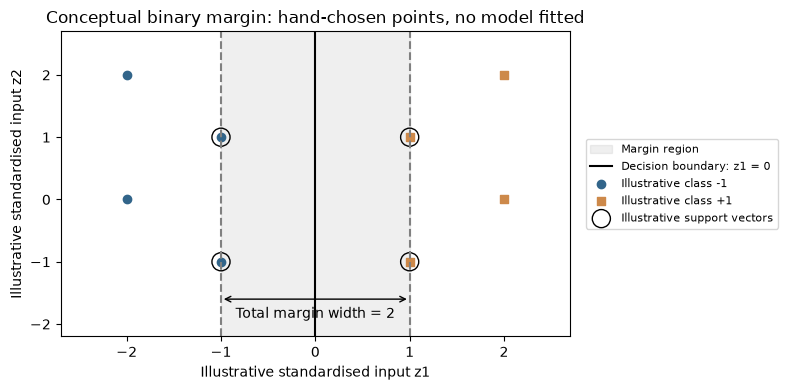

In [6]:
# A geometry illustration only: no estimator is fitted in this cell.
negative = np.array([[-1, -1], [-1, 1], [-2, 0], [-2, 2]])
positive = np.array([[1, -1], [1, 1], [2, 0], [2, 2]])
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(-1, 1, color='grey', alpha=0.12, label='Margin region')
ax.axvline(0, color='black', label='Decision boundary: z1 = 0')
for boundary in [-1, 1]:
    ax.axvline(boundary, color='grey', linestyle='--')
ax.scatter(negative[:, 0], negative[:, 1], label='Illustrative class -1', color='#32658a')
ax.scatter(positive[:, 0], positive[:, 1], label='Illustrative class +1', color='#cd894a', marker='s')
support_example = np.vstack([negative[:2], positive[:2]])
ax.scatter(support_example[:, 0], support_example[:, 1], s=170,
           facecolors='none', edgecolors='black', label='Illustrative support vectors')
ax.annotate('', xy=(1, -1.6), xytext=(-1, -1.6),
            arrowprops={'arrowstyle': '<->', 'color': 'black'})
ax.text(0, -1.9, 'Total margin width = 2', ha='center')
ax.set(xlabel='Illustrative standardised input z1', ylabel='Illustrative standardised input z2',
       title='Conceptual binary margin: hand-chosen points, no model fitted',
       xlim=(-2.7, 2.7), ylim=(-2.2, 2.7))
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.tight_layout()
plt.show()

#### Soft margins and settings

Real classes can overlap. Instead of requiring perfect separation, a **soft margin** permits violations and penalises them. For one binary comparison, the objective is

$$\min_{w,b}\;\frac{1}{2}\lVert w\rVert^2+C\sum_i\max\bigl(0,1-y_i(w^Tz_i+b)\bigr).$$

The second term is **hinge loss**: it is zero when $y_if(z_i)\geq1$. A correctly classified point can still incur loss if it is inside the margin. For example, $y_i=+1$ and $f(z_i)=0.4$ gives loss $0.6$; $f(z_i)=1.4$ gives loss 0.

- **Learned during `fit`:** the boundary coefficients and intercept for each binary problem, represented through selected support vectors and learned weights. Support vectors are fit observations, not a special set taken from validation.
- **`C`:** penalty multiplier in the objective above; the inner grid compares 0.1, 1 and 10. Smaller `C` puts relatively more emphasis on a wide margin; larger `C` penalises violations more. Neither is automatically better on unseen data. Each candidate fit uses a fixed C; inner validation selects between them.
- **`kernel='linear'`:** uses $K(z_i,z_j)=z_i^Tz_j$, the dot product. It is not Pearson correlation. `gamma`, `degree` and `coef0` do not affect this linear kernel. We do not add an RBF experiment.
- **`tol=1e-3` and `max_iter=10000`:** solver stopping tolerance and iteration ceiling, not a number of epochs. Reaching the ceiling without convergence stops this notebook with an identifiable error.
- **Multiclass learning:** `SVC` fits one-versus-one internally: Adelie versus Chinstrap, Adelie versus Gentoo and Chinstrap versus Gentoo. Three pairwise classifiers vote for a species. Its default one-versus-rest decision-score layout does not change the internal pairwise fitting. No probability calibration is enabled.

**How is it trained?** `SVC` uses LIBSVM's decomposition/SMO-type optimisation of the constrained problem. You do not need its derivation to follow this experiment: `fit` solves for the boundary after scaling. It is neither the logistic L-BFGS procedure nor tree splitting, and we do not supply a gradient-descent learning rate. `StandardScaler` matters because the margin depends on the units of the measurements. It must be fitted inside each fold.



### 3.4 K-nearest neighbours (KNN)

**Idea.** Similar physical measurements may indicate the same species. To predict one new penguin, KNN finds the k closest **fit observations** and chooses the most frequent species among them. It uses all four measurements together, not a separate classifier for each column.

1. Fit StandardScaler on the fit rows: learn a mean and standard deviation for each measurement.
2. Transform the fit rows and store their scaled measurements and species labels in KNN.
3. Transform a held-out query using the **same** learned scaler.
4. Compute distances to stored fit rows, find k nearest neighbours, and count their labels.

For scaled measurements $z_j=(x_j-\mu_j)/s_j$, Euclidean distance is
$$d(z,z_i)=\sqrt{\sum_{j=1}^{4}(z_j-z_{ij})^2}.$$
With uniform votes, the estimated proportion for species c is
$$\hat p(c\mid z)=\frac{1}{k}\sum_{i\in N_k(z)}\mathbf{1}(y_i=c),\qquad
\hat y=\arg\max_c\hat p(c\mid z).$$
The indicator is 1 when a neighbour has species c and 0 otherwise. For example, labels Adelie, Adelie, Chinstrap with k=3 give proportions 2/3, 1/3, 0 and predict Adelie. These proportions are not automatically calibrated probabilities.

**What does `fit` learn?** The pipeline scaler learns means and scales. KNN itself retains the fit examples and may build a search structure; it does not minimise a coefficient loss with gradient descent. `predict` searches those stored examples without changing them. k is a hyperparameter, not something changed inside one KNN fit.

| Item | Setting in this study | Meaning |
|---|---|---|
| `n_neighbors` | Inner search: 3, 5, 9 | How many fit labels contribute. Small k follows local detail; larger k smooths the boundary. |
| `weights` | `uniform` | Each neighbour contributes equally. Distance-weighted voting exists but is not used. |
| `metric`, `p` | `minkowski`, 2 | This is Euclidean distance. No metric search is performed. |
| `algorithm` | `auto` | Library choice of neighbour-search implementation, not another predictive model. |
| Learned quantities | Scaler statistics; stored fit rows and labels | No learned slope or intercept in KNN. |

An odd k prevents some binary vote ties but **does not prevent all ties with three species**. Distance ties at the neighbour boundary can also make row order relevant. Fixed source order supports reproducibility. KNN is sensitive to scale, irrelevant dimensions, local outliers and sample density; a high-dimensional setting is harder than this four-input example. We scale to give the four measurements comparable units, not because scaling guarantees higher scores.



### 3.5 Random Forest

**Idea.** One tree can change considerably when its fit data change. A forest combines trees made different by two sources of randomness:

1. For each tree, draw a bootstrap sample: sample fit rows **with replacement**. With `max_samples=None`, there are as many draws as fit rows, but repeated IDs mean fewer distinct observations.
2. At each node, consider a random subset of inputs and search for a useful split using Gini impurity, as explained in the earlier tree section. Here `max_features='sqrt'` gives a nominal subset of two out of four inputs. The library may inspect more if necessary to find a valid split.
3. Grow each tree subject to the chosen depth and leaf limits. Each tree learns its own split features, thresholds and terminal class proportions.
4. For a new observation, obtain the three class probabilities from each tree and **average probabilities across all 100 trees**. Predict the class with the greatest average.

For T trees, scikit-learn calculates
$$\hat p_{RF}(c\mid x)=\frac{1}{T}\sum_{t=1}^{T}\hat p_t(c\mid x),\qquad
\hat y=\arg\max_c\hat p_{RF}(c\mid x).$$
The per-tree probability is the class proportion in its reached leaf, including bootstrap multiplicities. **This is not necessarily the same as taking a majority of the 100 hard class labels.**

For illustration, three trees with probabilities (0.51, 0.49, 0), (0.51, 0.49, 0), and (0, 1, 0) have hard labels Adelie, Adelie, Chinstrap. Hard voting would give Adelie, but the mean probabilities are (0.34, 0.66, 0), so this probability-averaging rule gives Chinstrap. This is a constructed arithmetic example, not an additional experiment.

| Item | Setting in this study | Meaning |
|---|---|---|
| `n_estimators` | 100, fixed | Number of fitted trees; not epochs or gradient steps. |
| `max_depth` | Inner search: 3 or `None` | Cap tree depth, or allow growth until other stopping rules apply. |
| `min_samples_leaf` | Inner search: 1 or 5 | Minimum observations required in a terminal leaf; larger leaves smooth predictions. |
| `max_features` | `sqrt`, fixed | Random input subset considered at each split. |
| `bootstrap`, `max_samples` | `True`, `None` | Fit-row resampling with replacement; full fit-size draws per tree. |
| `criterion`, `min_samples_split` | `gini`, 2 | Split quality and minimum node size for attempting a split. |
| `class_weight`, `ccp_alpha` | `None`, 0 | No class reweighting or cost-complexity post-pruning. |
| `random_state`, `n_jobs` | 42, 1 | Repeatable randomness; sequential computation. |
| Learned quantities | 100 trees: split rules and leaf proportions | Not a single coefficient vector. |

**What happens during training?** `fit` constructs the trees using greedy splits. There is no gradient-descent optimiser or learning rate here. The trees are not trained to correct earlier trees' residuals: that is a boosting idea, not this forest. Scaling is unnecessary because its individual trees split by thresholds; keeping original units also aids interpretation.

Diversity can reduce variance when trees are combined, but they are not statistically independent. More trees do not guarantee a higher score. Forests are less transparent than one small tree, and depth/leaf limits still matter. Out-of-bag assessment and feature-importance analysis are other analyses outside the scope of this study. The model can perform worse than a simpler classifier on this small dataset.

**Terminology:** KNN classifies using labelled neighbours. K-means, in notebook 03, finds centroids without species labels. The letter k appears in both names but the algorithms solve different problems.


## 4. Train and compare the classifier procedures

The dictionary below defines five unfitted estimators and their grids. `clone` starts a fresh estimator. In every outer round, **`search.fit(X_fit, y_fit)` is where training and inner selection happen**. With `refit=True`, the chosen pipeline is then refitted on that outer fit group. `search.predict(X_held)` assesses it without learning from the held-out rows.

There are 280 estimator fits for the nested five-family comparison: 17 candidate settings × 3 inner folds × 5 outer folds, plus 25 outer refits. Each forest fit constructs 100 trees. Five additional outer fits establish the majority reference. No extra fit is needed to inspect the retained first-round models.


In [7]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from time import perf_counter

families = {
    'Logistic regression': (Pipeline([('scale', StandardScaler()),
        ('model', LogisticRegression(solver='lbfgs', max_iter=1000))]), {'model__C': [0.1, 1, 10]}),
    'Linear SVM': (Pipeline([('scale', StandardScaler()),
        ('model', SVC(kernel='linear', max_iter=10000))]), {'model__C': [0.1, 1, 10]}),
    'Decision tree': (DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED),
        {'max_depth': [2, 3, 4, 5]}),
    'KNN': (Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier(weights='uniform', metric='minkowski', p=2, algorithm='auto'))]),
        {'model__n_neighbors': [3, 5, 9]}),
    'Random Forest': (RandomForestClassifier(n_estimators=100, max_features='sqrt', bootstrap=True,
        criterion='gini', max_samples=None, min_samples_split=2, class_weight=None, ccp_alpha=0.0,
        random_state=SEED, n_jobs=1), {'max_depth': [3, None], 'min_samples_leaf': [1, 5]}),
}
nested_predictions = pd.DataFrame(index=y_train.index, columns=families, dtype=object)
reference_oof = pd.Series(index=y_train.index, dtype=object)
nested_rows = []
first_outer_models = {}  # Retain existing fits for explanation; no extra search.
started = perf_counter()
for outer_round, (fit_pos, held_pos) in enumerate(folds, 1):
    X_fit, y_fit = X_train.iloc[fit_pos], y_train.iloc[fit_pos]
    X_held, y_held = X_train.iloc[held_pos], y_train.iloc[held_pos]
    assert set(X_fit.index).isdisjoint(X_held.index)
    assert set(X_fit.index).union(X_held.index).isdisjoint(test_ids)
    reference = DummyClassifier(strategy='most_frequent').fit(X_fit, y_fit)
    reference_oof.loc[X_held.index] = reference.predict(X_held)
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    for name, (estimator, grid) in families.items():
        search = GridSearchCV(clone(estimator), grid, scoring='f1_macro', cv=inner_cv,
                              refit=True, n_jobs=1, error_score='raise')
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            search.fit(X_fit, y_fit)  # Inner fits/select, then refit outer-fit rows only.
        if outer_round == 1:
            first_outer_models[name] = search.best_estimator_
        prediction = search.predict(X_held)  # Outer assessment, no further fit.
        nested_predictions.loc[X_held.index, name] = prediction
        nested_rows.append({'fold': outer_round, 'model': name,
            'inner_best_macro_F1': search.best_score_, 'settings': str(search.best_params_),
            'outer_accuracy': accuracy_score(y_held, prediction),
            'outer_macro_F1': f1_score(y_held, prediction, average='macro'),
            'fit_n': len(X_fit), 'held_n': len(X_held)})
assert nested_predictions.notna().all().all()
nested_results = pd.DataFrame(nested_rows)
nested_summary = nested_results.groupby('model', sort=False).agg(
    mean_outer_F1=('outer_macro_F1', 'mean'), sd_outer_F1=('outer_macro_F1', 'std'),
    mean_outer_accuracy=('outer_accuracy', 'mean'))
selected_family = nested_summary['mean_outer_F1'].idxmax()
print('Nested CV seconds:', round(perf_counter()-started, 2))
display(nested_results)
display(nested_summary.round(4))
print('Family selected using development only:', selected_family)


Nested CV seconds: 24.32


,fold,model,inner_best_macro_F1,settings,outer_accuracy,outer_macro_F1,fit_n,held_n
0,1,Logistic regression,0.976096,{'model__C': 10},1.000000,1.000000,218,55
1,1,Linear SVM,0.982491,{'model__C': 1},1.000000,1.000000,218,55
2,1,Decision tree,0.917335,{'max_depth': 2},0.981818,0.977591,218,55
3,1,KNN,0.969350,{'model__n_neighbors': 3},1.000000,1.000000,218,55
4,1,Random Forest,0.960543,"{'max_depth': 3, 'min_samples_leaf': 1}",0.963636,0.956364,218,55
5,2,Logistic regression,0.988918,{'model__C': 10},1.000000,1.000000,218,55
6,2,Linear SVM,0.988918,{'model__C': 10},0.981818,0.977324,218,55
7,2,Decision tree,0.882429,{'max_depth': 2},0.927273,0.918415,218,55
8,2,KNN,1.000000,{'model__n_neighbors': 3},1.000000,1.000000,218,55
9,2,Random Forest,0.977510,"{'max_depth': None, 'min_samples_leaf': 1}",0.963636,0.955808,218,55


,mean_outer_F1,sd_outer_F1,mean_outer_accuracy
model,,,
Logistic regression,0.9812,0.0257,0.9853
Linear SVM,0.9815,0.0195,0.9854
Decision tree,0.9052,0.0451,0.9229
KNN,0.9812,0.0257,0.9853
Random Forest,0.9483,0.0303,0.9598


Family selected using development only: Linear SVM


### 4.1 Common development results
All five rows above are from the same nested protocol. Logistic regression, linear SVM and KNN have very close mean external-fold F1; the selected family is not declared significantly better than the others. The tree and forest results describe these particular searches, not a universal algorithm ranking. Fold SD is descriptive, not a confidence interval.

The code below computes one confusion matrix per procedure from its 273 OOF predictions and reports precision, recall and F1 for every species. The reference uses the same outer held-out rows. These pooled scores are labelled separately from mean fold scores.


In [8]:
pooled_rows = []
assessment_predictions = {'Majority reference': reference_oof, **{name: nested_predictions[name] for name in families}}
for name, predictions in assessment_predictions.items():
    matrix = confusion_matrix(y_train, predictions, labels=CLASS_ORDER)
    assert matrix.sum() == len(y_train)
    tp = np.diag(matrix)
    manual_f1 = 2*tp/(matrix.sum(axis=0)+matrix.sum(axis=1))
    precision, recall, f1, support = precision_recall_fscore_support(
        y_train, predictions, labels=CLASS_ORDER, zero_division=0)
    np.testing.assert_allclose(manual_f1, f1)
    pooled_rows.append({'model': name, 'accuracy': accuracy_score(y_train, predictions),
                        'pooled_macro_F1': f1.mean()})
    print(name, ': pooled development confusion counts')
    display(pd.DataFrame(matrix, index=CLASS_ORDER, columns=CLASS_ORDER))
    display(pd.DataFrame({'precision':precision,'recall':recall,'F1':f1,'support':support}, index=CLASS_ORDER).round(4))
pooled_classification = pd.DataFrame(pooled_rows).set_index('model')
print('Pooled OOF scores, not mean fold scores:')
display(pooled_classification.round(4))


Majority reference : pooled development confusion counts


,Adelie,Chinstrap,Gentoo
Adelie,121,0,0
Chinstrap,54,0,0
Gentoo,98,0,0


,precision,recall,F1,support
Adelie,0.4432,1.0,0.6142,121
Chinstrap,0.0000,0.0,0.0000,54
Gentoo,0.0000,0.0,0.0000,98


Logistic regression : pooled development confusion counts


,Adelie,Chinstrap,Gentoo
Adelie,120,1,0
Chinstrap,3,51,0
Gentoo,0,0,98


,precision,recall,F1,support
Adelie,0.9756,0.9917,0.9836,121
Chinstrap,0.9808,0.9444,0.9623,54
Gentoo,1.0000,1.0000,1.0000,98


... (10 outputs left out)

,Adelie,Chinstrap,Gentoo
Adelie,117,4,0
Chinstrap,5,47,2
Gentoo,0,0,98


,precision,recall,F1,support
Adelie,0.9590,0.9669,0.9630,121
Chinstrap,0.9216,0.8704,0.8952,54
Gentoo,0.9800,1.0000,0.9899,98


Pooled OOF scores, not mean fold scores:


,accuracy,pooled_macro_F1
model,,
Majority reference,0.4432,0.2047
Logistic regression,0.9853,0.9820
Linear SVM,0.9853,0.9820
Decision tree,0.9231,0.9072
KNN,0.9853,0.9820
Random Forest,0.9597,0.9494


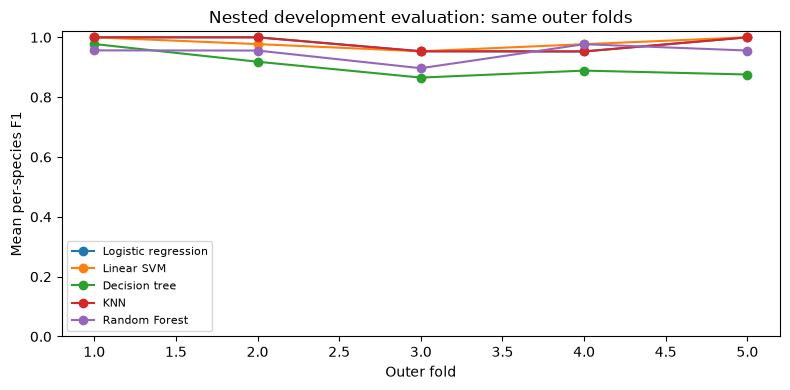

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in families:
    part = nested_results.loc[nested_results['model'].eq(name)]
    ax.plot(part['fold'], part['outer_macro_F1'], marker='o', label=name)
ax.set(xlabel='Outer fold', ylabel='Mean per-species F1', ylim=(0, 1.02),
       title='Nested development evaluation: same outer folds')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()


## 5. Inspect fitted models
The following examples use outer round 1 and its first held-out observation, selected by position rather than score. Those estimators were already selected and refitted in the common loop. Their query is absent from fitting and scaler learning. This is explanation of learned quantities, not another search or a final all-development fit.

### 5.1 Logistic coefficients and probabilities
The selected first-round C and its coefficient matrix are printed below. We calculate softmax probabilities directly from scaled inputs and fitted coefficients, then compare them with the pipeline output. Coefficient units refer to standardised inputs. A model probability does not establish calibration.


In [10]:
first_fit_pos, first_held_pos = folds[0]
explain_fit = X_train.iloc[first_fit_pos]
explain_labels = y_train.iloc[first_fit_pos]
query = X_train.iloc[first_held_pos[:1]]
assert set(query.index).isdisjoint(explain_fit.index)
first_logistic = first_outer_models['Logistic regression']
log_scaler = first_logistic.named_steps['scale']
log_estimator = first_logistic.named_steps['model']
np.testing.assert_allclose(log_scaler.mean_, explain_fit.mean())
z_query = log_scaler.transform(query)
scores = z_query @ log_estimator.coef_.T + log_estimator.intercept_
probabilities = np.exp(scores-scores.max(axis=1, keepdims=True))
probabilities /= probabilities.sum(axis=1, keepdims=True)
np.testing.assert_allclose(probabilities, first_logistic.predict_proba(query))
print('Outer-round-1 C:', log_estimator.C)
display(pd.DataFrame(log_estimator.coef_, index=log_estimator.classes_, columns=FEATURES).round(4))
display(pd.Series(log_estimator.intercept_, index=log_estimator.classes_, name='intercept').round(4))
display(pd.DataFrame(probabilities, columns=log_estimator.classes_, index=query.index))


Outer-round-1 C: 10


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
Adelie,-4.4218,2.8114,-0.4787,1.1757
Chinstrap,3.8367,-0.0742,-1.0359,-2.5185
Gentoo,0.5851,-2.7372,1.5145,1.3429


Adelie       0.3356
Chinstrap   -0.2119
Gentoo      -0.1236
Name: intercept, dtype: float64

,Adelie,Chinstrap,Gentoo
4,0.99998,0.000019,5.666619e-07


### 5.2 Tree rules and node purity
Each node shows a learned measurement threshold, Gini impurity and fitting-row counts. True branches go left. The first outer tree's selected depth is printed rather than assumed. We independently recalculate parent and child Gini from the outer-fit labels. The displayed rules belong to this fitted tree, not every tree or a causal mechanism.


Selected depth cap / actual depth / leaves: 2 2 4


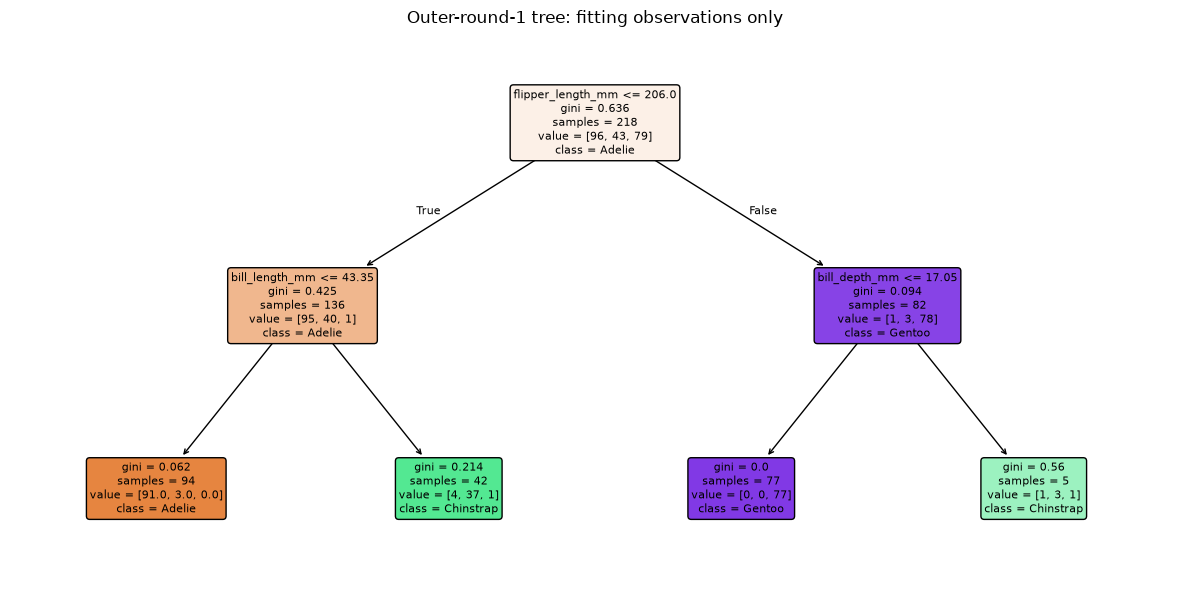

,n,gini,Adelie,Chinstrap,Gentoo
group,,,,,
parent,218,0.6358,96,43,79
left,136,0.4255,95,40,1
right,82,0.0937,1,3,78


Root measurement / threshold: flipper_length_mm 206.0
Weighted child Gini / gain: 0.3006907059086781 0.33515644500454467
Held-out query / prediction / recorded species: 4 Adelie Adelie


In [11]:
from sklearn.tree import plot_tree, export_text
first_tree = first_outer_models['Decision tree']
print('Selected depth cap / actual depth / leaves:', first_tree.max_depth, first_tree.get_depth(), first_tree.get_n_leaves())
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(first_tree, feature_names=FEATURES, class_names=first_tree.classes_.tolist(),
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Outer-round-1 tree: fitting observations only'); plt.tight_layout(); plt.show()
feature = first_tree.tree_.feature[0]; threshold = first_tree.tree_.threshold[0]
left = explain_fit.iloc[:, feature].le(threshold)
root_rows = []
for group, labels in [('parent', explain_labels), ('left', explain_labels.loc[left]), ('right', explain_labels.loc[~left])]:
    counts = labels.value_counts().reindex(CLASS_ORDER, fill_value=0)
    gini = 1-np.square(counts/len(labels)).sum()
    root_rows.append({'group':group,'n':len(labels),'gini':gini, **counts.to_dict()})
root_check = pd.DataFrame(root_rows).set_index('group')
np.testing.assert_allclose(root_check.loc['parent','gini'], first_tree.tree_.impurity[0])
weighted_child_gini = (root_check.loc[['left','right'],'n']*root_check.loc[['left','right'],'gini']).sum()/len(explain_fit)
display(root_check.round(4))
print('Root measurement / threshold:', FEATURES[feature], threshold)
print('Weighted child Gini / gain:', weighted_child_gini, root_check.loc['parent','gini']-weighted_child_gini)
print('Held-out query / prediction / recorded species:', query.index[0], first_tree.predict(query)[0], y_train.loc[query.index[0]])


### 5.3 SVM support observations
Support vectors are fitting observations used to represent pairwise boundaries, not a set of held-out mistakes. Their class counts, selected C and solver iterations are printed. Each support ID must belong to the outer fit group and be absent from the held-out group and reserved test. Decision scores are not calibrated probabilities.


In [12]:
first_svm = first_outer_models['Linear SVM']
svm_estimator = first_svm.named_steps['model']
support_ids = explain_fit.index[svm_estimator.support_]
assert set(support_ids).issubset(explain_fit.index)
assert set(support_ids).isdisjoint(X_train.iloc[first_held_pos].index)
assert set(support_ids).isdisjoint(test_ids)
assert svm_estimator.fit_status_ == 0
print('Outer-round-1 C / maximum pairwise iterations:', svm_estimator.C, svm_estimator.n_iter_.max())
display(pd.Series(svm_estimator.n_support_, index=svm_estimator.classes_, name='fit_support_observations'))
print('Held-out query prediction:', first_svm.predict(query)[0])


Outer-round-1 C / maximum pairwise iterations: 1 108


Adelie       9
Chinstrap    9
Gentoo       4
Name: fit_support_observations, dtype: int32

Held-out query prediction: Adelie


### 5.4 KNN neighbours and distances

We retain the already-fitted KNN pipeline from **outer round 1**, selected by round number. The query is the first held-out source row in that round, not an example selected for an attractive prediction. It was absent from the stored fit rows and from scaler fitting. No additional fit occurs here.

Read the table of k neighbours: their source IDs, scaled four-input distances and recorded labels. Recompute distances with NumPy and check the uniform class proportions against `predict_proba`. The two-dimensional plot shows only bill length and depth; the actual nearest-neighbour calculation uses **all four scaled measurements**. It is an illustrative projection, not the full distance geometry or a decision boundary.


Outer round 1: fit rows / held-out query source ID / selected k: 218 4 3


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
4,36.7,19.3,193.0,3450.0


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,distance_scaled_4D,species
fit_source_ID,,,,,,
16,38.7,19.0,195.0,3450.0,0.423510,Adelie
86,36.3,19.5,190.0,3800.0,0.510279,Adelie
96,38.1,18.6,190.0,3700.0,0.575278,Adelie


,neighbour_count,uniform_probability
species,,
Adelie,3,1.0
Chinstrap,0,0.0
Gentoo,0,0.0


Predicted / recorded species: Adelie Adelie


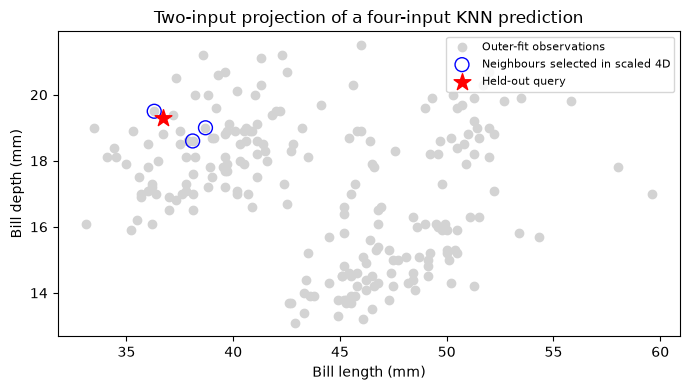

In [13]:
first_fit_pos, first_held_pos = folds[0]
explain_fit = X_train.iloc[first_fit_pos]
explain_labels = y_train.iloc[first_fit_pos]
query = X_train.iloc[first_held_pos[:1]]
assert query.index[0] not in explain_fit.index and query.index[0] not in test_ids
knn_pipeline = first_outer_models['KNN']
knn_scaler = knn_pipeline.named_steps['scale']
knn = knn_pipeline.named_steps['model']
fit_scaled = knn_scaler.transform(explain_fit)
query_scaled = knn_scaler.transform(query)
np.testing.assert_allclose(knn_scaler.mean_, explain_fit.mean())
distances, positions = knn.kneighbors(query_scaled)
manual_distances = np.sqrt(np.square(fit_scaled-query_scaled[0]).sum(axis=1))
np.testing.assert_allclose(distances[0], manual_distances[positions[0]], atol=1e-10)
neighbours = explain_fit.iloc[positions[0]].copy()
neighbours['distance_scaled_4D'] = distances[0]
neighbours['species'] = explain_labels.iloc[positions[0]].to_numpy()
neighbours.index.name = 'fit_source_ID'
counts = neighbours['species'].value_counts().reindex(knn.classes_, fill_value=0)
manual_probabilities = counts.to_numpy()/knn.n_neighbors
np.testing.assert_allclose(manual_probabilities, knn.predict_proba(query_scaled)[0])
manual_label = knn.classes_[manual_probabilities.argmax()]
assert manual_label == knn_pipeline.predict(query)[0]
print('Outer round 1: fit rows / held-out query source ID / selected k:',
      len(explain_fit), query.index[0], knn.n_neighbors)
display(query)
display(neighbours)
display(pd.DataFrame({'neighbour_count': counts, 'uniform_probability': manual_probabilities}))
print('Predicted / recorded species:', manual_label, y_train.loc[query.index[0]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(explain_fit['bill_length_mm'], explain_fit['bill_depth_mm'],
           color='lightgrey', label='Outer-fit observations')
ax.scatter(neighbours['bill_length_mm'], neighbours['bill_depth_mm'],
           facecolors='none', edgecolors='blue', s=100, label='Neighbours selected in scaled 4D')
ax.scatter(query['bill_length_mm'], query['bill_depth_mm'], marker='*',
           color='red', s=160, label='Held-out query')
ax.set(xlabel='Bill length (mm)', ylabel='Bill depth (mm)',
       title='Two-input projection of a four-input KNN prediction')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()


### 5.5 Forest bootstrap samples and mean probabilities

Use the forest already selected and refitted in outer round 1 and the **same query**. Print the learned depth and number of leaves for the first five trees, their bootstrap draw counts and distinct source-row counts. A draw position refers to an outer-fit row, never a held-out/test row. Repeated positions are expected, not duplicate-data cleaning errors.

Each tree receives the query, reaches a leaf and returns three probabilities. The mean over **all 100 trees**, not just the displayed first five, must equal `forest.predict_proba`. The class with the largest mean must equal `forest.predict`. This is an inspection of existing fitted objects, not a new model comparison.


In [14]:
forest = first_outer_models['Random Forest']
query_array = query.to_numpy()
tree_probabilities = np.vstack([tree.predict_proba(query_array)[0] for tree in forest.estimators_])
manual_forest_probability = tree_probabilities.mean(axis=0)
np.testing.assert_allclose(manual_forest_probability, forest.predict_proba(query)[0])
manual_forest_label = forest.classes_[manual_forest_probability.argmax()]
assert manual_forest_label == forest.predict(query)[0]
tree_rows = []
for number, (tree, draws) in enumerate(zip(forest.estimators_, forest.estimators_samples_)):
    source_ids = explain_fit.index.to_numpy()[draws]
    assert set(source_ids).issubset(explain_fit.index)
    assert set(source_ids).isdisjoint(query.index) and set(source_ids).isdisjoint(test_ids)
    tree_rows.append({'tree': number+1, 'bootstrap_draws': len(draws),
        'distinct_fit_rows': len(np.unique(draws)), 'learned_depth': tree.get_depth(),
        'learned_leaves': tree.get_n_leaves()})
print('Trees / chosen depth cap / chosen minimum leaf:',
      len(forest.estimators_), forest.max_depth, forest.min_samples_leaf)
display(pd.DataFrame(tree_rows).head(5))
print('First five trees only (not selected by score):')
display(pd.DataFrame(tree_probabilities[:5], columns=forest.classes_,
                     index=pd.Index(range(1, 6), name='tree')).round(4))
print('Average across all trees:')
display(pd.Series(manual_forest_probability, index=forest.classes_, name='mean_probability').round(4))
print('Predicted / recorded species:', manual_forest_label, y_train.loc[query.index[0]])
print('Probability-averaging rule verified; no optimiser or new fit was called.')


Trees / chosen depth cap / chosen minimum leaf: 100 3 1


,tree,bootstrap_draws,distinct_fit_rows,learned_depth,learned_leaves
0,1,218,141,3,6
1,2,218,139,3,7
2,3,218,136,3,4
3,4,218,143,3,6
4,5,218,134,3,6


First five trees only (not selected by score):


,Adelie,Chinstrap,Gentoo
tree,,,
1,1.0000,0.0000,0.0
2,0.3333,0.6667,0.0
3,1.0000,0.0000,0.0
4,1.0000,0.0000,0.0
5,0.8608,0.1392,0.0


Average across all trees:


Adelie       0.9153
Chinstrap    0.0844
Gentoo       0.0003
Name: mean_probability, dtype: float64

Predicted / recorded species: Adelie Adelie
Probability-averaging rule verified; no optimiser or new fit was called.


## 6. Regression: predict body mass

**Question:** can bill length, bill depth and flipper length predict **body mass in grams** better than a simple constant reference?

Classification predicted a species label. Regression predicts a number. We now define **three inputs**, `bill_length_mm`, `bill_depth_mm` and `flipper_length_mm`, and response `body_mass_g`. **Body mass leaves the input matrix.** Species, island, sex and year are not regression predictors in this regression task. We do not reuse classification accuracy or F1 to judge grams.

The original 275 training / 69 reserved-test allocation is unchanged. It was stratified by species when fixed earlier; it is not a new mass-stratified split. Within training we check complete records for these three inputs **and** the mass response. Here the same two source rows are incomplete, leaving 273 eligible observations. This coincidence does not make input and response roles interchangeable. Nine observations with missing sex remain usable.

The separate variables below avoid overwriting the classification inputs, labels or folds. No source row is deleted or filled, and this development-preparation block does not inspect final-test eligibility or mass values. Those are used only in section 7.
`train` is the original 275-row development table. `reg_eligible` marks rows with all three inputs and the response recorded; `reg_training` copies those 273 rows. `X_reg` contains the three input columns and `y_reg` contains their recorded weights. These lines prepare data; they do not train a model.


In [15]:
REG_FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']
REG_TARGET = 'body_mass_g'
reg_required = REG_FEATURES + [REG_TARGET]
reg_eligible = train[reg_required].notna().all(axis=1)
reg_training = train.loc[reg_eligible].copy()
X_reg = reg_training[REG_FEATURES].copy()
y_reg = reg_training[REG_TARGET].copy()
reg_excluded_ids = train.index[~reg_eligible].tolist()
assert REG_TARGET not in X_reg.columns and 'species' not in X_reg.columns
assert X_reg.index.equals(y_reg.index)
assert X_reg.notna().all().all() and y_reg.notna().all()
assert set(X_reg.index).isdisjoint(test_ids)
assert len(reg_training) + len(reg_excluded_ids) == len(train)
assert len(reg_training) == 273 and reg_excluded_ids == [3, 271]
print('Regression input matrix / numeric response:', X_reg.shape, y_reg.shape)
print('Eligible / excluded training rows:', len(reg_training), len(reg_excluded_ids))
print('Excluded source IDs:', reg_excluded_ids)
print('Inputs in mm; response in grams. The original CSV and split are unchanged.')

Regression input matrix / numeric response: (273, 3) (273,)
Eligible / excluded training rows: 273 2
Excluded source IDs: [3, 271]
Inputs in mm; response in grams. The original CSV and split are unchanged.


### 6.1 Linear regression and the median reference

For one input, a line is $\hat y=\beta_0+\beta_1x$. We use **multiple linear regression**, with three inputs:

$$\widehat{\mathrm{mass}}=\beta_0+\beta_1\,\mathrm{bill\ length}+\beta_2\,\mathrm{bill\ depth}+\beta_3\,\mathrm{flipper\ length}.$$

The inputs are in millimetres and the output is in grams. The intercept $\beta_0$ and three coefficients $\beta_j$ are **learned parameters**, not values we choose by hand. A coefficient describes a change in predicted grams per additional millimetre **holding the other two inputs fixed**. It is not a causal effect. Correlated measurements can make individual coefficients difficult to interpret. The intercept at three zero measurements is a mathematical reference, not a plausible penguin.

**Where does learning come from?** Define a fit residual $e_i=y_i-\hat y_i$. Ordinary least squares (OLS) chooses the parameters that minimise the **residual sum of squares** on fit observations:

$$\mathrm{RSS}(\beta)=\sum_{i\in\mathrm{fit}}(y_i-\hat y_i)^2.$$

With $n$ fixed, minimising RSS is equivalent to minimising its mean, MSE. Squaring penalises large errors more. For instance, residuals 100 g and -200 g contribute $100^2+(-200)^2=50{,}000$ square grams. The numerical least-squares solver computes coefficients from the fit table; **this `LinearRegression` implementation does not run our own gradient-descent loop**. Training happens at `.fit`, just as for classifiers, but the objective is different.

**What do we choose?** `LinearRegression(fit_intercept=True, positive=False)` learns an intercept and allows either coefficient sign. There is no regularisation `C` or `alpha`, learning rate or epoch count here. Numerical solver tolerances are implementation settings, not a search for predictive hyperparameters. The runtime versions are recorded at the top of the notebook.

We retain original measurement units and do not scale or impute in this OLS model. Scaling is not required for this small, unregularised least-squares fit; it would change coefficient units. Any later learned preprocessing must still be fitted within each fit subset. No polynomial terms, interactions, feature selection or coefficient significance tests are added.

**Reference:** `DummyRegressor(strategy='median')` learns the fit subset's median mass and predicts it for every held-out observation, ignoring the measurements. The median minimises absolute error among constant predictions on the fit set. It is a relevant reference because our main metric is MAE; it is not the optimal constant for squared error, for which the fit mean would be the reference.

### 6.2 Regression metrics

For $n$ held-out observations, with $e_i=y_i-\hat y_i$:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|e_i|,\qquad \mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i e_i^2}.$$

**MAE is the main metric.** It is the average absolute error in grams: lower is better. It does not mean every prediction is within that distance. **RMSE** is also in grams, but gives larger errors more influence. In the 100 g / -200 g example, MAE is 150 g and RMSE is $\sqrt{25{,}000}\approx158.1$ g.

We also report **$R^2$** as a supplementary dimensionless summary:

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

Here $\bar y$ is the mean of the observations being scored, used only in the metric denominator; it is not fitted into either predictor. A score of 1 is perfect on these observations, 0 matches the squared error of their constant mean, and negative values are possible. It is **not classification accuracy**, a correlation coefficient, or the proportion of predictions that are correct. Do not assume that held-out $R^2$ lies between 0 and 1. We compare both regressors on the same rows and read MAE/RMSE before $R^2$.

**Pearson r versus R-squared:** Pearson r measures signed linear association between two variables, from -1 to +1. Our held-out, three-input regression R-squared is not automatically r squared. In simple OLS with an intercept on the fit sample the identity holds for input/response correlation; it must not be assumed here.

### 6.3 Fit and assess on five development folds

We use **`KFold(n_splits=5, shuffle=True, random_state=42)`**, a separate saved fold list for regression. We do not stratify continuous mass values. There are again three validation groups of 55 and two of 54 observations, with fit sizes 218 or 219; membership need not match the classification folds.

In each round, construct a fresh median reference and a fresh linear regressor. Fit both on exactly the same fit rows, then predict exactly the same held-out rows. Each of the 273 observations receives one prediction from each method that was fitted without it. Fold medians, coefficients and intercepts come from fit labels only. Validation mass is used to calculate errors after prediction.

The visible loop records fit and validation MAE, validation RMSE and R-squared. Fit errors describe the data the method learned from; they are not substituted for validation errors. Pooling all held-out predictions and averaging fold scores are different summaries. Fold standard deviations describe variation, not confidence intervals.

These are fixed teaching models, not a hyperparameter search or nested cross-validation. The final 69 observations remain reserved. This question was informed by training EDA; the scores are development evidence rather than a reserved-test evaluation.

In [16]:
from sklearn.model_selection import KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

reg_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_folds = list(reg_cv.split(X_reg))
reg_oof = pd.DataFrame(np.nan, index=y_reg.index, columns=['Median reference', 'Linear regression'])
reg_coverage = np.zeros(len(X_reg), dtype=int)
reg_fold_rows = []

for fold_number, (fit_positions, validation_positions) in enumerate(reg_folds, start=1):
    X_fit, y_fit = X_reg.iloc[fit_positions], y_reg.iloc[fit_positions]
    X_validation, y_validation = X_reg.iloc[validation_positions], y_reg.iloc[validation_positions]
    assert set(X_fit.index).isdisjoint(X_validation.index)
    assert set(X_fit.index).union(X_validation.index) == set(X_reg.index)
    assert set(X_fit.index).union(X_validation.index).isdisjoint(test_ids)
    models = {
        'Median reference': DummyRegressor(strategy='median'),
        'Linear regression': LinearRegression(fit_intercept=True, positive=False),
    }
    for model_name, reg_model in models.items():
        # TRAIN HERE: learn a fit median, or the intercept and three OLS coefficients.
        reg_model.fit(X_fit, y_fit)
        # PREDICT HERE: validation rows change no fitted quantities.
        held_out = reg_model.predict(X_validation)
        fit_predictions = reg_model.predict(X_fit)
        assert np.isfinite(held_out).all()
        reg_oof.loc[X_validation.index, model_name] = held_out
        reg_fold_rows.append({
            'fold': fold_number, 'model': model_name,
            'fit_n': len(X_fit), 'validation_n': len(X_validation),
            'fit_MAE_g': mean_absolute_error(y_fit, fit_predictions),
            'validation_MAE_g': mean_absolute_error(y_validation, held_out),
            'validation_RMSE_g': root_mean_squared_error(y_validation, held_out),
            'validation_R2': r2_score(y_validation, held_out),
        })
        if model_name == 'Median reference':
            np.testing.assert_allclose(held_out, y_fit.median())
        if fold_number == 1 and model_name == 'Linear regression':
            first_regressor = reg_model
            first_regression_coefficients = pd.Series(reg_model.coef_, index=REG_FEATURES,
                                                      name='grams_per_mm')
            first_regression_intercept = float(reg_model.intercept_)
            first_regression_example = X_validation.iloc[[0]].copy()
            first_regression_actual = float(y_validation.iloc[0])
    reg_coverage[validation_positions] += 1

assert (reg_coverage == 1).all() and reg_oof.notna().all().all()
reg_fold_results = pd.DataFrame(reg_fold_rows).set_index(['fold', 'model'])
display(reg_fold_results.round(3))
print('Round 1 learned coefficients: grams per mm, conditional on the other inputs')
display(first_regression_coefficients.round(3).to_frame())
print('Round 1 intercept (g):', round(first_regression_intercept, 3))
print('Round 1 validation example, source ID:', int(first_regression_example.index[0]))
display(first_regression_example)
manual_mass = first_regression_intercept + float(
    first_regression_example.to_numpy()[0] @ first_regression_coefficients.to_numpy())
np.testing.assert_allclose(manual_mass, first_regressor.predict(first_regression_example)[0])
print('Intercept + three coefficient contributions (g):', round(manual_mass, 2))
print('Recorded mass (g):', first_regression_actual)
print('Residual = recorded - predicted (g):', round(first_regression_actual - manual_mass, 2))

fit_n  validation_n  fit_MAE_g  validation_MAE_g  \
fold model                                                                 
1    Median reference     218            55    692.317           600.455   
     Linear regression    218            55    324.752           303.162   
2    Median reference     218            55    653.555           755.682   
     Linear regression    218            55    311.255           353.066   
3    Median reference     218            55    654.472           740.909   
     Linear regression    218            55    310.760           362.613   
4    Median reference     219            54    682.306           629.630   
     Linear regression    219            54    329.741           288.811   
5    Median reference     219            54    673.744           668.056   
     Linear regression    219            54    322.610           318.872   

                        validation_RMSE_g  validation_R2  
fold model                                                
1    Median reference             738.403         -0.000  
     Linear regression            392.716          0.717  
2    Median reference             902.608         -0.152  
     Linear regression            444.327          0.721  
3    Median reference             898.041         -0.074  
     Linear regression            443.191          0.738  
4    Median reference             784.146         -0.034  
     Linear regression            361.420          0.780  
5    Median reference             779.029         -0.004  
     Linear regression            391.329          0.747

Round 1 learned coefficients: grams per mm, conditional on the other inputs


,grams_per_mm
bill_length_mm,-0.327
bill_depth_mm,36.404
flipper_length_mm,54.363


Round 1 intercept (g): -7313.17
Round 1 validation example, source ID: 8


,bill_length_mm,bill_depth_mm,flipper_length_mm
8,34.1,18.1,193.0


Intercept + three coefficient contributions (g): 3826.68
Recorded mass (g): 3475.0
Residual = recorded - predicted (g): -351.68


### 6.4 Compare held-out errors

Calculate a single summary from all 273 held-out predictions for each method. We keep the units in the column names. Then show the mean and standard deviation of the five fold scores separately. The main question is whether using measurements reduces **validation MAE** compared with the median reference.

The direct calculations below check MAE, RMSE and R-squared from residuals. They do not train another model. A positive residual means recorded mass exceeds predicted mass: the model **underestimates** that observation. A negative residual means it **overestimates** it. We show a few rows in original source order to connect formulas, predictions and real observations.

In [17]:
reg_summary_rows = []
for model_name in reg_oof.columns:
    predictions = reg_oof[model_name]
    errors = y_reg - predictions
    mae = mean_absolute_error(y_reg, predictions)
    rmse = root_mean_squared_error(y_reg, predictions)
    r2 = r2_score(y_reg, predictions)
    np.testing.assert_allclose(mae, np.abs(errors).mean())
    np.testing.assert_allclose(rmse, np.sqrt(np.square(errors).mean()))
    np.testing.assert_allclose(r2, 1 - np.square(errors).sum() / np.square(y_reg - y_reg.mean()).sum())
    reg_summary_rows.append({'model': model_name, 'MAE_g': mae, 'RMSE_g': rmse, 'R2': r2})
reg_summary = pd.DataFrame(reg_summary_rows).set_index('model')
print('Pooled held-out regression scores; 273 identical observations per method')
display(reg_summary.round(3))
print('Separate fold summaries; standard deviation is descriptive')
display(reg_fold_results.groupby('model')[['validation_MAE_g', 'validation_RMSE_g',
                                           'validation_R2']].agg(['mean', 'std']).round(3))
reg_examples = pd.DataFrame({'recorded_mass_g': y_reg,
                             'median_prediction_g': reg_oof['Median reference'],
                             'linear_prediction_g': reg_oof['Linear regression']})
reg_examples['linear_residual_g'] = y_reg - reg_oof['Linear regression']
print('First five source rows, not selected by prediction quality')
display(reg_examples.head().round(2))

Pooled held-out regression scores; 273 identical observations per method

,MAE_g,RMSE_g,R2
model,,,
Median reference,679.167,823.484,-0.048
Linear regression,325.462,408.100,0.743


Separate fold summaries; standard deviation is descriptive


validation_MAE_g         validation_RMSE_g          \
                              mean     std              mean     std   
model                                                                  
Linear regression          325.305  31.725           406.596  36.157   
Median reference           678.946  67.896           820.445  75.060   

                  validation_R2         
                           mean    std  
model                                   
Linear regression         0.741  0.025  
Median reference         -0.053  0.063

First five source rows, not selected by prediction quality


,recorded_mass_g,median_prediction_g,linear_prediction_g,linear_residual_g
0,3750.0,4050.0,3213.70,536.30
2,3250.0,4050.0,3920.53,-670.53
4,3450.0,3987.5,3843.68,-393.68
5,3650.0,4050.0,3709.88,-59.88
6,3625.0,4050.0,3209.39,415.61


### 6.5 Diagnostic figures

**Observed versus predicted:** the diagonal is perfect prediction. Predictions below it underestimate mass; predictions above it overestimate. The median reference produces almost horizontal bands because each fold predicts one fit median. A tighter diagonal cloud for the linear model indicates lower errors on these observations, not a guarantee for new populations.

**Residual versus predicted:** each point is an out-of-fold error from the linear model, using `recorded - predicted`. The zero line means no error. A curve could suggest missing nonlinear structure; a funnel could suggest changing error spread. This small visual check does not prove linearity, equal variance, normality or independent errors. It combines five fitted models, so its mean residual need not be exactly zero, unlike a fit-table OLS identity with an intercept.

All eligible observations, including large errors, are shown. No plot changes the target, removes a row or chooses a new model. We do not label these as final-test figures.

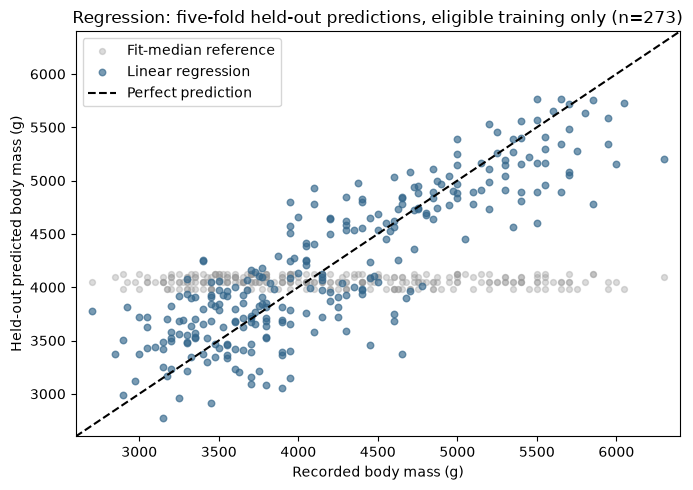

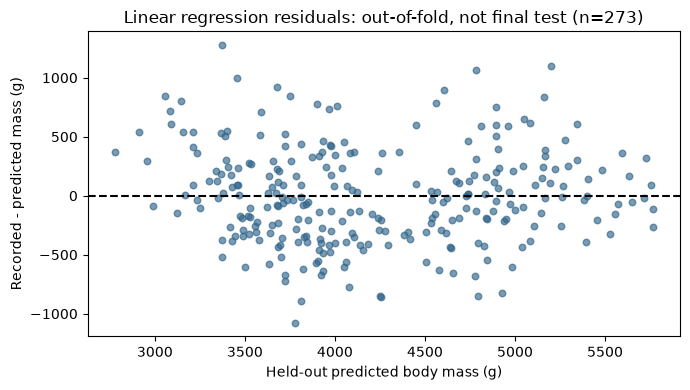

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_reg, reg_oof['Median reference'], alpha=0.35, s=18,
           label='Fit-median reference', color='#999999')
ax.scatter(y_reg, reg_oof['Linear regression'], alpha=0.65, s=22,
           label='Linear regression', color='#32658a')
limits = [min(y_reg.min(), reg_oof.min().min()) - 100,
          max(y_reg.max(), reg_oof.max().max()) + 100]
ax.plot(limits, limits, color='black', linestyle='--', label='Perfect prediction')
ax.set(xlabel='Recorded body mass (g)', ylabel='Held-out predicted body mass (g)',
       title='Regression: five-fold held-out predictions, eligible training only (n=273)',
       xlim=limits, ylim=limits)
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(reg_oof['Linear regression'], y_reg - reg_oof['Linear regression'],
           alpha=0.65, s=22, color='#32658a')
ax.axhline(0, color='black', linestyle='--')
ax.set(xlabel='Held-out predicted body mass (g)', ylabel='Recorded - predicted mass (g)',
       title='Linear regression residuals: out-of-fold, not final test (n=273)')
fig.tight_layout()
plt.show()

### 6.6 Interpretation

**Do measurements help here?** Yes, in this fixed development comparison. The median reference has **MAE 679.17 g, RMSE 823.48 g and R-squared -0.048**. Linear regression has **MAE 325.46 g, RMSE 408.10 g and R-squared 0.743** on the same 273 held-out observations. The MAE reduction is approximately **52.1%** relative to that reference. It is not a 52.1% improvement over every possible model or a guaranteed error for an individual penguin.

**Why is the reference's R-squared negative?** Each fold predicts its fit median, not the scored observations' mean used in the R-squared denominator. Its held-out squared error is slightly greater than that denominator. The negative value is valid, not a software error. The reference was chosen for absolute-error evaluation, not to minimise RMSE.

**Are results stable across folds?** Linear validation MAE ranges from **288.81 to 362.61 g**, compared with fit MAE **310.76 to 329.74 g**. It improves on the median reference in each fold. Different subsets can make validation error lower than fit error. The pooled scores and five fold scores describe this particular development exercise; neither is a confidence interval or a final-test score.

**Can we read the fitted formula?** In round 1 the learned intercept is approximately **-7313.17 g**, and the coefficients are **-0.33, 36.40 and 54.36 g/mm** for bill length, bill depth and flipper length. The displayed source-row-8 example gives **3826.68 g predicted versus 3475 g recorded**, a residual of **-351.68 g**: an overestimate. Printed coefficients are rounded for reading; the code uses full-precision arrays to calculate 3826.68 g. This is one fold's fitted formula, not the final all-development regressor. The small negative bill-length coefficient is conditional on the other two correlated inputs; it does not prove bill length is useless or has a causal negative effect. Zero physical measurements are outside the data, so the intercept has no standalone biological interpretation.

**What do the figures show?** Measurement-based predictions follow the diagonal more closely than the almost horizontal reference. They still miss some observations substantially: the held-out residual range is approximately **-1075.68 to +1276.00 g**. For example, the 6300 g observation is predicted at 5198.52 g. All such observations remain in the data. MAE is an average, and the larger RMSE reflects the greater weight of large errors. Residuals appear on both sides of zero; this plot alone does not establish normality, constant variance, independence or the absence of nonlinear structure.

**What we learn:** changing the response changes the input set, loss and evaluation metrics. OLS learns coefficients by minimising fit squared error, while we judge its predictions primarily by held-out absolute error in grams. Neither coefficient magnitude nor a p-value automatically selects features. No new data, test inspection, imputation, transformation search, regression tree or regularisation search was introduced. These small-sample results describe within-sample generalisation, not other islands, years or penguin populations.

## 7. Refit and assess on the reserved test

This is the first modelling use of the reserved test. Running this notebook again reproduces the same evaluation, but must not become a way to tune against the test. The task-specific complete-case rule is unchanged. The selected classifier, reference, OLS and median are fitted using development only. No family is changed after test scores are shown.


Reserved / classifier eligible / regression eligible: 69 69 69
Classifier exclusions: []
Selected family and final development settings: Linear SVM {'model__C': 10}


,n,accuracy,macro_F1
model,,,
Majority reference,69,0.4348,0.2020
Linear SVM,69,0.9855,0.9829


,precision,recall,F1,support
Adelie,1.0000,0.9667,0.9831,30
Chinstrap,0.9333,1.0000,0.9655,14
Gentoo,1.0000,1.0000,1.0000,25


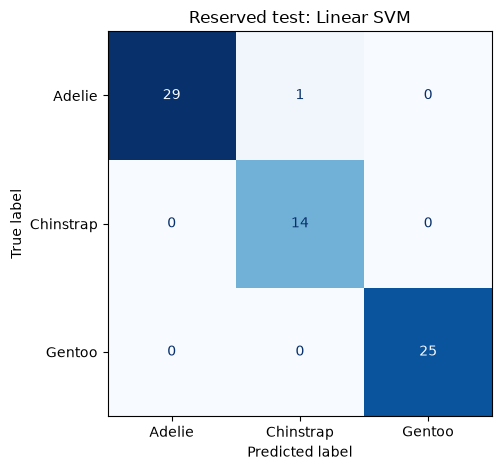

,n,MAE_g,RMSE_g,R2
model,,,,
Median reference,69,644.565,793.948,-0.021
Linear regression,69,276.834,348.582,0.803


In [19]:
estimator, grid = families[selected_family]
final_search = GridSearchCV(clone(estimator), grid, scoring='f1_macro',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    refit=True, n_jobs=1, error_score='raise')
with warnings.catch_warnings():
    warnings.simplefilter('error', ConvergenceWarning)
    final_search.fit(X_train, y_train)
final_reference = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
final_regressor = LinearRegression().fit(X_reg, y_reg)
final_median = DummyRegressor(strategy='median').fit(X_reg, y_reg)
# TEST OPENS HERE: the protocol and all fits above are already fixed.
test = penguins.loc[test_ids].copy()
test_view = test.loc[test[FEATURES + [TARGET]].notna().all(axis=1)].copy()
reg_test = test.loc[test[REG_FEATURES + [REG_TARGET]].notna().all(axis=1)].copy()
X_test, y_test = test_view[FEATURES], test_view[TARGET]
assert set(X_test.index).isdisjoint(X_train.index)
print('Reserved / classifier eligible / regression eligible:', len(test), len(test_view), len(reg_test))
print('Classifier exclusions:', sorted(set(test.index)-set(test_view.index)))
print('Selected family and final development settings:', selected_family, final_search.best_params_)
final_predictions = final_search.predict(X_test)
reference_predictions = final_reference.predict(X_test)
test_classification = pd.DataFrame([
    {'model': name, 'n': len(y_test), 'accuracy': accuracy_score(y_test, pred),
     'macro_F1': f1_score(y_test, pred, labels=CLASS_ORDER, average='macro', zero_division=0)}
    for name, pred in [('Majority reference', reference_predictions), (selected_family, final_predictions)]
]).set_index('model')
display(test_classification.round(4))
p, r, f, support = precision_recall_fscore_support(y_test, final_predictions,
    labels=CLASS_ORDER, zero_division=0)
display(pd.DataFrame({'precision': p, 'recall': r, 'F1': f, 'support': support}, index=CLASS_ORDER).round(4))
ConfusionMatrixDisplay.from_predictions(y_test, final_predictions, labels=CLASS_ORDER,
    cmap='Blues', colorbar=False)
plt.title('Reserved test: '+selected_family); plt.tight_layout(); plt.show()
reg_test_predictions = final_regressor.predict(reg_test[REG_FEATURES])
reg_reference_predictions = final_median.predict(reg_test[REG_FEATURES])
test_regression = pd.DataFrame([
    {'model': name, 'n': len(reg_test), 'MAE_g': mean_absolute_error(reg_test[REG_TARGET], pred),
     'RMSE_g': root_mean_squared_error(reg_test[REG_TARGET], pred),
     'R2': r2_score(reg_test[REG_TARGET], pred)}
    for name, pred in [('Median reference', reg_reference_predictions), ('Linear regression', reg_test_predictions)]
]).set_index('model')
display(test_regression.round(3))


## 8. Uncertainty and limitations

For accuracy $\hat p=k/n$, the Wilson interval uses $z=1.96$ and centre $(\hat p+z^2/(2n))/(1+z^2/n)$, with half-width $z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}/(1+z^2/n)$. It avoids reporting certainty after a perfect small test.

**Paired classification comparison:** count observations where only the selected model is right ($b$) and only the reference is right ($c$). Exact McNemar uses a binomial test of $b$ successes in $b+c$ discordant pairs under probability 0.5. This tests equal error rates for this pre-specified pair, not all families or equal macro-F1.

**Regression bootstrap:** resample row positions with replacement, using the same positions for both predictions and truth. Recompute MAE and the reference-minus-OLS MAE difference. The 2.5th and 97.5th percentiles give an approximate 95% interval. Positive MAE reduction favours OLS. This does not refit models. We assume observations are sufficiently independent and representative; collection structure can weaken that assumption. A small test and a bootstrap cannot establish generalisation to new populations.


**Sampling limits.** Wilson uses an approximate binomial model for accuracy. These observations were allocated by a species-stratified split, and the simplified table does not identify every collection dependency. Our pooled Wilson and row-bootstrap intervals are simple working approximations; they do not model the full collection design or fix class counts in each resample. The paired comparison also assumes sufficiently independent observation pairs. A 95% confidence interval refers to approximate long-run coverage under its assumptions, not a 95% probability that a fixed unknown parameter lies inside this particular interval. Final-model selection, fitting variability and uncertainty about a different population are outside these intervals.


In [20]:
from scipy.stats import binomtest
def wilson(correct, total):
    z = 1.959963984540054
    phat = correct/total
    denominator = 1+z*z/total
    centre = (phat+z*z/(2*total))/denominator
    half = z*np.sqrt(phat*(1-phat)/total+z*z/(4*total**2))/denominator
    return centre-half, centre+half

for name, prediction in [('Majority reference', reference_predictions), (selected_family, final_predictions)]:
    correct = int(np.sum(np.asarray(y_test)==prediction))
    print(name, 'correct:', correct, '/', len(y_test), 'Wilson 95%:', wilson(correct, len(y_test)))
model_right = final_predictions == y_test.to_numpy()
reference_right = reference_predictions == y_test.to_numpy()
b = int(np.sum(model_right & ~reference_right)); c = int(np.sum(~model_right & reference_right))
paired_p = binomtest(b, b+c, p=0.5).pvalue if b+c else 1.0
print('Exact McNemar: model-only correct / reference-only correct / p:', b, c, paired_p)

rng = np.random.default_rng(SEED)
positions = rng.integers(0, len(reg_test), size=(5000, len(reg_test)))
absolute_errors = np.abs(reg_test[REG_TARGET].to_numpy()-reg_test_predictions)
reference_errors = np.abs(reg_test[REG_TARGET].to_numpy()-reg_reference_predictions)
bootstrap_mae = absolute_errors[positions].mean(axis=1)
bootstrap_gain = (reference_errors[positions]-absolute_errors[positions]).mean(axis=1)
mae_interval = np.quantile(bootstrap_mae, [0.025, 0.975])
gain_interval = np.quantile(bootstrap_gain, [0.025, 0.975])
print('OLS MAE, percentile 95% interval (g):', absolute_errors.mean(), mae_interval)
print('Reference-minus-OLS MAE, paired percentile 95% interval (g):',
      (reference_errors-absolute_errors).mean(), gain_interval)
assert np.isclose(absolute_errors.mean(), test_regression.loc['Linear regression', 'MAE_g'])


Majority reference correct: 30 / 69 Wilson 95%: (np.float64(0.32432802635131497), np.float64(0.5521159638472569))
Linear SVM correct: 68 / 69 Wilson 95%: (np.float64(0.9223687753885529), np.float64(0.9974370753554117))
Exact McNemar: model-only correct / reference-only correct / p: 39 1 7.457856554538012e-11
OLS MAE, percentile 95% interval (g): 276.8343727267791 [228.37398705 326.64791142]
Reference-minus-OLS MAE, paired percentile 95% interval (g): 367.73084466452525 [249.68126248 484.86826721]


## 9. Conclusions and references

Read the common nested classification assessment, fixed-regression development assessment and reserved-test results in their proper roles. A high score does not establish usefulness in other islands, years or collection settings. Final model choice uses development only; test results are reported without a further search. Classification intervals concern accuracy, not macro-F1; the single paired test concerns selected model versus majority reference. Regression intervals describe conditional test-sample uncertainty. No claim that one measurement-based classifier significantly beats all others is supported by this design.

Notebook 03 addresses descriptive unsupervised learning separately. Species labels never enter its fitted scaler, PCA or K-means. Personal learning conclusions should be written by the author after reviewing and understanding these results.

References: [nested CV](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [KNN](https://scikit-learn.org/stable/modules/neighbors.html), [forests](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees), [binomial test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html).


**Observed final results:** the fixed selection rule chose linear SVM, C=10; 68/69 test observations are correct (accuracy 98.55%, mean species F1 0.9829). The Wilson accuracy interval is 92.24–99.74%. OLS test MAE is 276.83 g, with conditional paired-bootstrap interval 228.37–326.65 g. No post-test tuning was performed. The tiny development advantage of SVM over logistic/KNN is not evidence of superiority.

### Method references

- [F1 and per-class metrics](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html)
- [logistic regression and its objective](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)
- [LogisticRegression settings](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Decision trees and Gini](https://scikit-learn.org/stable/modules/tree.html#mathematical-formulation)
- [DecisionTreeClassifier settings](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [SVM user guide](https://scikit-learn.org/stable/modules/svm.html)
- [SVC implementation and settings](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [median reference](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html)
- [regression evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)

- [Grid search and hyperparameter selection](https://scikit-learn.org/stable/modules/grid_search.html)

### AI assistance

AI assistance was used for explanations, Python drafts, debugging and editing. The author is responsible for reviewing, understanding and explaining the submitted work. The reports record the checks performed and a documented correction. No personal learning reflection is written on the author's behalf.
